In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
flights = pd.read_csv("flights.csv", nrows=50000)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
display(flights.head())

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Number of rows:", flights.shape[0])
print("Number of columns:", flights.shape[1])

Number of rows: 50000
Number of columns: 31


In [8]:
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 50000 non-null  int64  
 1   MONTH                50000 non-null  int64  
 2   DAY                  50000 non-null  int64  
 3   DAY_OF_WEEK          50000 non-null  int64  
 4   AIRLINE              50000 non-null  object 
 5   FLIGHT_NUMBER        50000 non-null  int64  
 6   TAIL_NUMBER          49941 non-null  object 
 7   ORIGIN_AIRPORT       50000 non-null  object 
 8   DESTINATION_AIRPORT  50000 non-null  object 
 9   SCHEDULED_DEPARTURE  50000 non-null  int64  
 10  DEPARTURE_TIME       48896 non-null  float64
 11  DEPARTURE_DELAY      48896 non-null  float64
 12  TAXI_OUT             48873 non-null  float64
 13  WHEELS_OFF           48873 non-null  float64
 14  SCHEDULED_TIME       50000 non-null  int64  
 15  ELAPSED_TIME         48753 non-null 

In [9]:
missing = flights.isnull().sum()

print(missing[missing > 0])

TAIL_NUMBER               59
DEPARTURE_TIME          1104
DEPARTURE_DELAY         1104
TAXI_OUT                1127
WHEELS_OFF              1127
ELAPSED_TIME            1247
AIR_TIME                1247
WHEELS_ON               1161
TAXI_IN                 1161
ARRIVAL_TIME            1161
ARRIVAL_DELAY           1247
CANCELLATION_REASON    48862
AIR_SYSTEM_DELAY       34592
SECURITY_DELAY         34592
AIRLINE_DELAY          34592
LATE_AIRCRAFT_DELAY    34592
WEATHER_DELAY          34592
dtype: int64


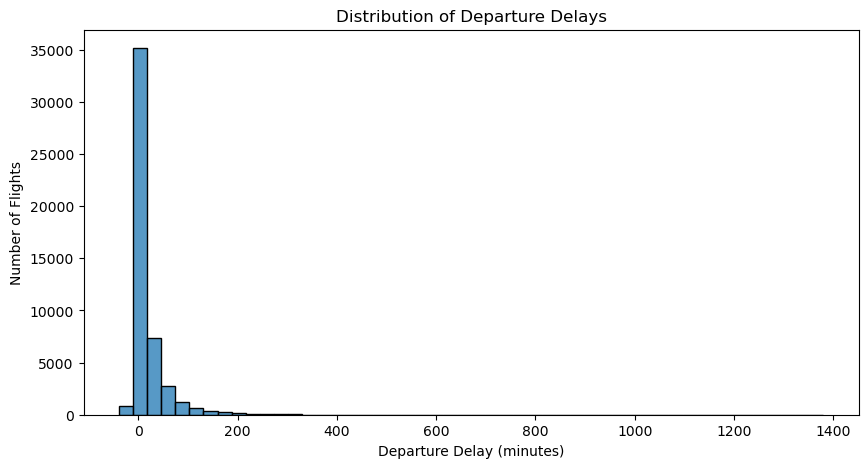

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=flights,
    x="DEPARTURE_DELAY",
    bins=50
)

plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()

In [11]:
print(flights["CANCELLED"].value_counts())

CANCELLED
0    48862
1     1138
Name: count, dtype: int64


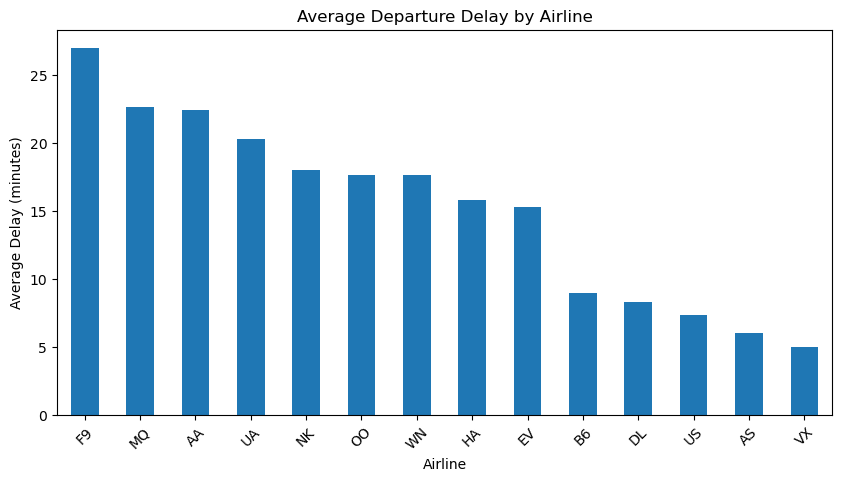

In [12]:
airline_delay = flights.groupby("AIRLINE")["DEPARTURE_DELAY"].mean()

airline_delay = airline_delay.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
airline_delay.plot(kind="bar")

plt.title("Average Departure Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=45)

plt.show()

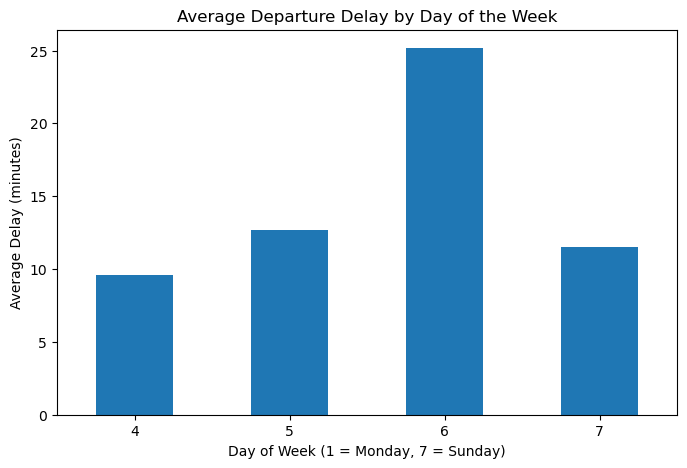

In [13]:
day_delay = flights.groupby("DAY_OF_WEEK")["DEPARTURE_DELAY"].mean()

plt.figure(figsize=(8, 5))
day_delay.plot(kind="bar")

plt.title("Average Departure Delay by Day of the Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=0)
plt.show()

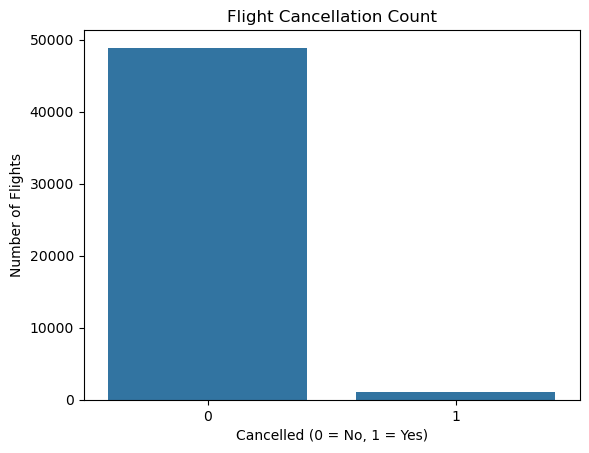

In [14]:
sns.countplot(data=flights, x="CANCELLED")

plt.title("Flight Cancellation Count")
plt.xlabel("Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()

In [15]:
print("Duplicate rows:", flights.duplicated().sum())

Duplicate rows: 0


In [16]:
print(flights["DEPARTURE_DELAY"].describe())

count    48896.000000
mean        15.596020
std         40.758942
min        -39.000000
25%         -3.000000
50%          1.000000
75%         19.000000
max       1380.000000
Name: DEPARTURE_DELAY, dtype: float64


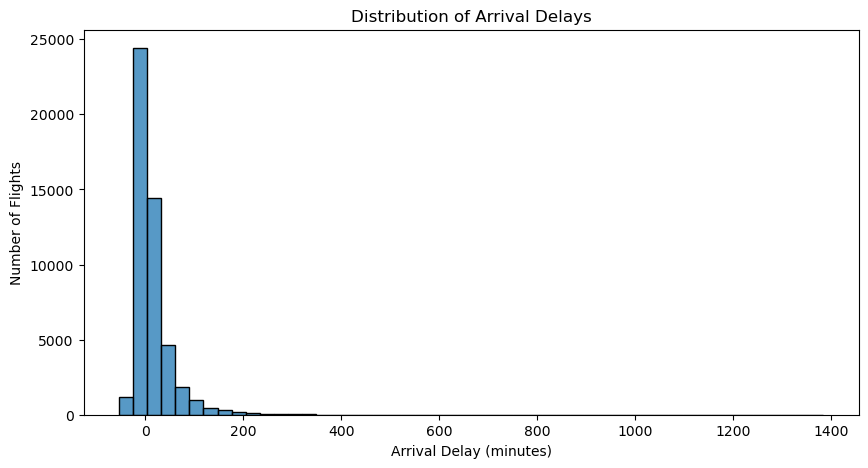

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(data=flights, x="ARRIVAL_DELAY", bins=50)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()

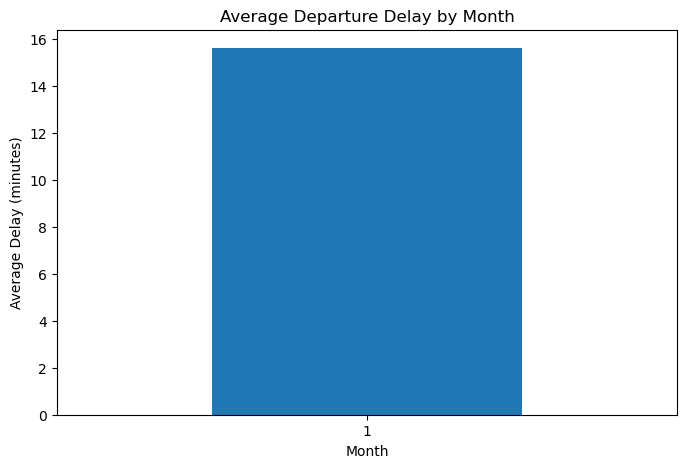

In [18]:
monthly_delay = flights.groupby("MONTH")["DEPARTURE_DELAY"].mean()

plt.figure(figsize=(8, 5))
monthly_delay.plot(kind="bar")

plt.title("Average Departure Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=0)
plt.show()

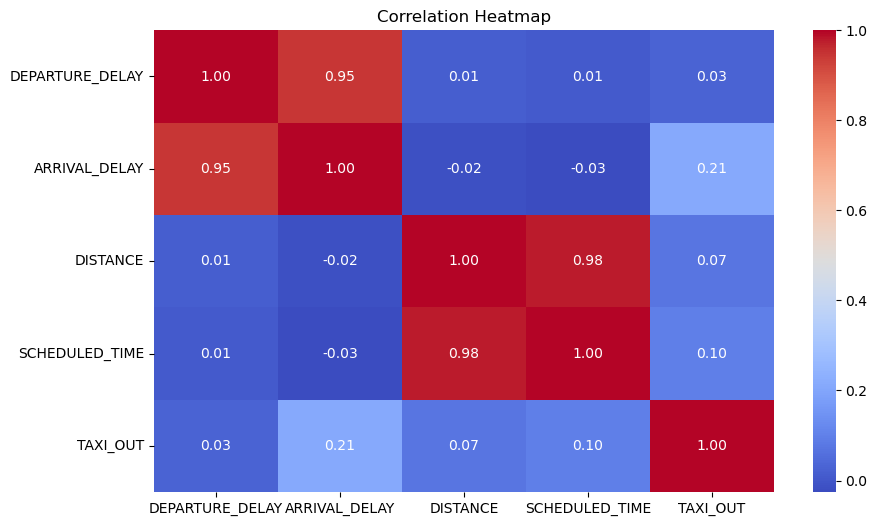

In [19]:
plt.figure(figsize=(10, 6))

columns = ["DEPARTURE_DELAY", "ARRIVAL_DELAY",
           "DISTANCE", "SCHEDULED_TIME", "TAXI_OUT"]

sns.heatmap(flights[columns].corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()